In [ ]:
# # WORK6 - THE WORK4 CROSS-VALIDATION WITH MILEAGE HELD FIXED
#
# work4_fair_evaluation.ipynb tells broken cars from not-broken ones with a car-level AUC of 0.94 when every snippet is used. The proposal's worry is that part of that comes from the fleet rather than the battery: the broken cars are the high-mileage, heavily recorded ones, and 99.9 % of snippets beyond 110,000 km come from broken cars. work5_low_mileage_and_jumps.ipynb looked at the raw signals below 50,000 km and found that, car by car, they barely tell the two groups apart (per-signal car-level AUC 0.35 to 0.54).
#
# This notebook is the direct test. It runs the work4 pipeline unchanged (same feature engineering, same tuned XGBoost settings, same repeated grouped 7-fold cross-validation over cars with the cutoff chosen on validation cars only), but only on snippets below 50,000 km, keeping the cars that have at least 100 such snippets. Every car is then seen at the same age, so the model can only use what the battery signals say at that age.
#
# Sections:
#
# 1. Feature engineering (copied from work4)
# 2. Cut the table at 50,000 km
# 3. The work4 cross-validation, as a function
# 4. Results at 50,000 km, next to the all-mileage numbers from work4
# 5. One decision per car (graph)
# 6. Does the cap matter? 30,000, 50,000 and 80,000 km, and no cap
# 7. Sanity check: shuffled car labels
# 8. Conclusion
#
# Only ../data/final_training_dataset.csv is needed (produced by prework.ipynb). With REPEATS = 5 the notebook takes about 6 minutes on an 8-core CPU, and about 3 minutes with REPEATS = 1.

In [1]:
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, f1_score

pd.set_option("display.width", 200)

DATA = "../data/final_training_dataset.csv"
REPEATS = 5              # repeats of the 7-fold car split for the reported numbers (1 for a quick check)
OUTER, INNER = 7, 4      # outer folds over cars, inner folds for the cutoff; same as work4
MILEAGE_CAP = 50_000     # only snippets below this mileage are used
MIN_ROWS = 100           # a car needs at least this many snippets below the cap to stay in
BLUE, ORANGE = "#2a78d6", "#eb6834"   # not broken (0), broken (1), same colours as work4 and work5

df = pd.read_csv(DATA)
print(df.shape, "| cars:", df["car"].nunique(), "| broken cars:", int(df.groupby("car")["label"].first().sum()))

(176327, 11) | cars: 49 | broken cars: 16


In [ ]:
# ---------------- 1. Feature engineering (copied from work4) ----------------
#
# The seven base features, the five engineered ones and the tuned XGBoost settings are copied from work4. The rolling features are computed on the full table, per car in mileage order, *before* the table is cut. A rolling window only looks back at the car's earlier snippets, so a snippet below the cap gets exactly the same window either way; the cut just removes the later rows.

In [2]:
BASE7 = ["avg_cell_voltage", "max_cell_voltage", "min_cell_voltage", "avg_current", "avg_temp", "max_temp", "voltage_gap"]
ENG5 = ["rolling_max_temp_mean_10", "rolling_voltage_gap_mean_10", "rolling_voltage_gap_std_10", "thermal_load", "voltage_temp_ratio"]
TUNED = dict(learning_rate=0.1, max_depth=5, n_estimators=200, subsample=0.8, random_state=42, eval_metric="logloss")

def engineer_battery_features(df):
    d = df.copy().sort_values(by=["car", "mileage"]).reset_index(drop=True)
    g = d.groupby("car")
    d["rolling_max_temp_mean_10"] = g["max_temp"].transform(lambda x: x.rolling(10, min_periods=1).mean())
    d["rolling_voltage_gap_mean_10"] = g["voltage_gap"].transform(lambda x: x.rolling(10, min_periods=1).mean())
    d["rolling_voltage_gap_std_10"] = g["voltage_gap"].transform(lambda x: x.rolling(10, min_periods=1).std()).fillna(0)
    d["thermal_load"] = d["max_temp"] * np.abs(d["avg_current"])
    d["voltage_temp_ratio"] = d["voltage_gap"] / (d["max_temp"] + 1e-5)
    return d

def scores(y, pred):
    y = np.asarray(y); pred = np.asarray(pred).astype(int)
    tn = int(((y == 0) & (pred == 0)).sum()); fp = int(((y == 0) & (pred == 1)).sum())
    fn = int(((y == 1) & (pred == 0)).sum()); tp = int(((y == 1) & (pred == 1)).sum())
    n = tn + fp + fn + tp
    return dict(TN=tn, FP=fp, FN=fn, TP=tp, accuracy=(tn + tp) / n, recall=tp / max(tp + fn, 1),
                false_alarm=fp / max(tn + fp, 1), majority_guess=max(tn + fp, tp + fn) / n)

fe = engineer_battery_features(df)
print(fe.shape, "| features:", len(BASE7), "base +", len(ENG5), "engineered")

(176327, 16) | features: 7 base + 5 engineered


In [ ]:
# ---------------- 2. Cut the table at 50,000 km ----------------
#
# Snippets at or above the cap are dropped, and so is any car left with fewer than MIN_ROWS snippets below it. At 50,000 km that removes car 514 (5 snippets below the cap) and cars 546 and 547 (27 and 28 snippets in total), leaving 46 cars: 31 not broken and 15 broken, the same cars as in work5. Four of the broken cars (533, 534, 539, 541) spent their whole recorded life below the cap; the other eleven are the high-mileage cars cut off at 50,000 km.

In [3]:
def cut_at(fe, cap, min_rows=MIN_ROWS):
    # snippets below `cap` km, from the cars that have at least `min_rows` of them; cap=None keeps the whole table (all 49 cars, as in work4)
    if cap is None:
        return fe.reset_index(drop=True)
    low = fe[fe["mileage"] < cap]
    rows = low.groupby("car").size()
    return low[low["car"].isin(rows.index[rows >= min_rows])].reset_index(drop=True)

def car_counts(data):
    car_label = data.groupby("car")["label"].first()
    return dict(cars=len(car_label), not_broken=int((car_label == 0).sum()), broken=int((car_label == 1).sum()),
                snippets=len(data), broken_share=float(data["label"].mean()))

low = cut_at(fe, MILEAGE_CAP)
n = car_counts(low)
print(f"Below {MILEAGE_CAP:,} km: {n['cars']} cars ({n['not_broken']} not broken, {n['broken']} broken), "
      f"{n['snippets']:,} snippets, {100 * n['broken_share']:.1f}% of them from broken cars")
print("Dropped for having fewer than", MIN_ROWS, "snippets below the cap:", sorted(int(c) for c in set(fe["car"].unique()) - set(low["car"].unique())))
per_car = low.groupby("car").agg(snippets=("label", "size"), label=("label", "first"), first_km=("mileage", "min"), last_km=("mileage", "max"))
print("\nSnippets per car below the cap, by label (0 = not broken, 1 = broken):")
per_car.groupby("label")["snippets"].describe().round(0)

Below 50,000 km: 46 cars (31 not broken, 15 broken), 89,577 snippets, 38.2% of them from broken cars
Dropped for having fewer than 100 snippets below the cap: [514, 546, 547]

Snippets per car below the cap, by label (0 = not broken, 1 = broken):


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,31.0,1786.0,1888.0,117.0,456.0,793.0,2343.0,6496.0
1,15.0,2281.0,1713.0,317.0,1047.0,1648.0,3437.0,6085.0


In [ ]:
# ---------------- 3. The work4 cross-validation, as a function ----------------
#
# This is the loop from section 5 of work4, wrapped in a function so it can be run on several cuts of the table. The procedure itself is unchanged:
#
# - Cars are dealt into 7 folds, broken and not-broken cars separately, so every fold has both. Each fold takes a turn as the unseen test cars.
# - Inside the training cars a second grouped split (4 folds) gives out-of-fold predictions. The snippet cutoff is chosen on those with the work3 rule (best F1 among cutoffs with recall of at least 0.75). The test cars are never used to choose it.
# - One decision per car: a car's snippet probabilities are averaged, and the car cutoff is chosen on the training cars' out-of-fold averages (best balanced accuracy).
# - The whole thing is repeated REPEATS times with different car shuffles (seeds 100, 101, ...).
#
# Three feature sets are run: the 7 original features, the 12 features (with the 5 engineered ones), and the 7 features plus mileage.

In [4]:
CONFIGS = {
    "7 features":           (BASE7, False),
    "12 features":          (BASE7 + ENG5, False),
    "7 features + mileage": (BASE7 + ["mileage"], False),
}

def fit_predict(Xtr, ytr, Xte, use_weight):
    params = dict(TUNED)
    if use_weight:
        params["scale_pos_weight"] = (ytr == 0).sum() / (ytr == 1).sum()
    return xgb.XGBClassifier(**params).fit(Xtr, ytr).predict_proba(Xte)[:, 1]

def pick_cutoff(y_val, p_val):
    best_t, best_f1 = 0.5, -1
    for t in np.round(np.arange(0.02, 0.92, 0.02), 2):
        pred = (p_val >= t).astype(int)
        if pred[y_val == 1].mean() >= 0.75:
            f1 = f1_score(y_val, pred, zero_division=0)
            if f1 > best_f1:
                best_f1, best_t = f1, t
    return float(best_t)

def pick_car_cutoff(car_p, car_y):
    best_t, best_b = 0.5, -1
    for t in np.round(np.arange(0.10, 0.91, 0.01), 2):
        pred = car_p >= t
        b = (pred[car_y == 1].mean() + (~pred[car_y == 0]).mean()) / 2
        if b > best_b:
            best_b, best_t = b, t
    return float(best_t)

def run_cv(data, configs, repeats, tag=""):
    # work4's repeated grouped cross-validation on `data`.
    # Returns one row per test fold, one row per held-out car, and every held-out snippet prediction.
    y = data["label"].values; cars = data["car"].values
    car_label = data.groupby("car")["label"].first()

    def car_folds(rep):
        rng = np.random.RandomState(100 + rep); fold_of = {}
        for lab in (1, 0):
            cs = car_label[car_label == lab].index.values.copy(); rng.shuffle(cs)
            for i, c in enumerate(cs):
                fold_of[c] = i % OUTER
        f = np.array([fold_of[c] for c in cars])
        for k in range(OUTER):
            yield np.where(f != k)[0], np.where(f == k)[0]

    fold_rows, car_rows, pred_rows = [], [], []
    for rep in range(repeats):
        for fold, (tr, te) in enumerate(car_folds(rep)):
            ytr, yte = y[tr], y[te]
            for name, (feats, use_weight) in configs.items():
                X = data[feats].values
                p_val = np.zeros(len(tr))
                for itr, iva in GroupKFold(n_splits=INNER).split(X[tr], ytr, groups=cars[tr]):
                    p_val[iva] = fit_predict(X[tr][itr], ytr[itr], X[tr][iva], use_weight)
                cutoff = pick_cutoff(ytr, p_val)
                p = fit_predict(X[tr], ytr, X[te], use_weight)
                fold_rows.append(dict(config=name, rep=rep, fold=fold, cutoff=cutoff, AUC=roc_auc_score(yte, p), **scores(yte, p >= cutoff)))
                # one decision per car: average the snippet probabilities of each car
                train_cars = pd.DataFrame({"car": cars[tr], "p": p_val, "y": ytr}).groupby("car").agg(p=("p", "mean"), y=("y", "first"))
                t_car = pick_car_cutoff(train_cars["p"].values, train_cars["y"].values)
                test_cars = pd.DataFrame({"car": cars[te], "p": p, "y": yte, "flag": (p >= cutoff).astype(int)}).groupby("car").agg(
                    mean_p=("p", "mean"), label=("y", "first"), rows=("p", "size"), share_flagged=("flag", "mean")).reset_index()
                test_cars["config"] = name; test_cars["rep"] = rep; test_cars["fold"] = fold; test_cars["car_cutoff"] = t_car
                car_rows.append(test_cars)
                pred_rows.append(pd.DataFrame({"config": name, "rep": rep, "fold": fold, "car": cars[te], "y": yte, "p": p, "flag": (p >= cutoff).astype(int)}))
        print(f"{tag}repeat {rep + 1} of {repeats} done")
    return pd.DataFrame(fold_rows), pd.concat(car_rows, ignore_index=True), pd.concat(pred_rows, ignore_index=True)

folds, car_results, preds = run_cv(low, CONFIGS, REPEATS, tag=f"below {MILEAGE_CAP:,} km, ")

below 50,000 km, repeat 1 of 5 done


below 50,000 km, repeat 2 of 5 done


below 50,000 km, repeat 3 of 5 done


below 50,000 km, repeat 4 of 5 done


below 50,000 km, repeat 5 of 5 done


In [ ]:
# ---------------- 4. Results at 50,000 km ----------------
#
# summarise boils the three result tables down to one row per feature set:
#
# - snippet AUC (pooled): all held-out snippet predictions of one repeat pooled together, then averaged over repeats. This is the 0.86 of work4.
# - fold AUC: the AUC of each test fold on its own, over all REPEATS x 7 folds. This is the 0.84 (0.66 to 0.92) of work4.
# - car AUC: each car's held-out snippet probabilities averaged into one number per car, then the AUC over cars; mean and range over repeats.
# - recall / false alarms: at the validation-chosen snippet cutoff of each fold, pooled over all held-out snippets of a repeat, then averaged over repeats. Recall is the share of broken-car snippets flagged, false alarms the share of not-broken-car snippets flagged.
# - broken caught / not broken flagged: cars whose average probability reaches the car cutoff chosen on that fold's training cars; averaged over repeats.
#
# The last row holds the all-mileage numbers from work4 (README row 6: 49 cars, 16 broken, 176,327 snippets) for comparison.

In [5]:
def summarise(folds, car_results, preds):
    out = []
    for name in dict.fromkeys(folds["config"]):
        f = folds[folds["config"] == name]
        pooled, by_car = [], []
        for rep, pr in preds[preds["config"] == name].groupby("rep"):
            pooled.append(dict(AUC=roc_auc_score(pr["y"], pr["p"]), **scores(pr["y"], pr["flag"])))
        for rep, c in car_results[car_results["config"] == name].groupby("rep"):
            s = scores(c["label"], c["mean_p"] >= c["car_cutoff"])
            by_car.append(dict(car_AUC=roc_auc_score(c["label"], c["mean_p"]), caught=s["TP"], flagged=s["FP"], n1=s["TP"] + s["FN"], n0=s["TN"] + s["FP"]))
        pooled, by_car = pd.DataFrame(pooled), pd.DataFrame(by_car)
        n0, n1 = int(by_car["n0"].iloc[0]), int(by_car["n1"].iloc[0])
        out.append({
            "config": name, "cars": n0 + n1, "broken cars": n1, "not-broken cars": n0,
            "snippets": int(pooled[["TN", "FP", "FN", "TP"]].iloc[0].sum()),
            "snippet AUC (pooled)": pooled["AUC"].mean(),
            "fold AUC mean": f["AUC"].mean(), "fold AUC range": f"{f['AUC'].min():.2f} to {f['AUC'].max():.2f}",
            "car AUC": by_car["car_AUC"].mean(), "car AUC range": f"{by_car['car_AUC'].min():.2f} to {by_car['car_AUC'].max():.2f}",
            "recall %": 100 * pooled["recall"].mean(), "false alarms %": 100 * pooled["false_alarm"].mean(),
            "accuracy %": 100 * pooled["accuracy"].mean(), "majority guess %": 100 * pooled["majority_guess"].mean(),
            "broken caught": f"{by_car['caught'].mean():.1f} of {n1}", "not broken flagged": f"{by_car['flagged'].mean():.1f} of {n0}",
            "snippet cutoff": f["cutoff"].mean(),
        })
    return pd.DataFrame(out).set_index("config")

# work4, all mileage: README row 6 and the car-level paragraph under the results table
WORK4 = pd.DataFrame([{
    "config": "work4: all mileage", "cars": 49, "broken cars": 16, "not-broken cars": 33, "snippets": 176327,
    "snippet AUC (pooled)": 0.86, "fold AUC mean": 0.84, "fold AUC range": "0.66 to 0.92",
    "car AUC": 0.94, "car AUC range": "0.92 to 0.97",
    "recall %": 88.2, "false alarms %": 38.0, "accuracy %": 76.7, "majority guess %": 56.2,
    "broken caught": "12.6 of 16", "not broken flagged": "6.0 of 33", "snippet cutoff": 0.29,
}]).set_index("config")

results = pd.concat([summarise(folds, car_results, preds), WORK4])
MAIN = ["cars", "broken cars", "snippet AUC (pooled)", "fold AUC mean", "fold AUC range", "car AUC", "recall %", "false alarms %", "broken caught", "not broken flagged"]
DETAIL = ["not-broken cars", "snippets", "car AUC range", "accuracy %", "majority guess %", "snippet cutoff"]
ROUND = {"snippet AUC (pooled)": 3, "fold AUC mean": 3, "car AUC": 3, "recall %": 1, "false alarms %": 1, "accuracy %": 1, "majority guess %": 1, "snippet cutoff": 2}
print(f"Below {MILEAGE_CAP:,} km, REPEATS = {REPEATS}; recall and false alarms at the validation-chosen snippet cutoff, pooled over snippets")
results[MAIN].round(ROUND)

Below 50,000 km, REPEATS = 5; recall and false alarms at the validation-chosen snippet cutoff, pooled over snippets


,cars,broken cars,snippet AUC (pooled),fold AUC mean,fold AUC range,car AUC,recall %,false alarms %,broken caught,not broken flagged
config,,,,,,,,,,
7 features,46,15,0.873,0.851,0.71 to 0.98,0.947,80.0,25.1,12.8 of 15,3.6 of 31
12 features,46,15,0.877,0.855,0.72 to 0.98,0.957,80.5,23.2,13.4 of 15,5.6 of 31
7 features + mileage,46,15,0.838,0.827,0.57 to 0.97,0.951,80.6,28.5,12.6 of 15,3.8 of 31
work4: all mileage,49,16,0.860,0.840,0.66 to 0.92,0.940,88.2,38.0,12.6 of 16,6.0 of 33


In [6]:
# the rest of the columns: accuracy against the majority guess, the spread of the car-level AUC over repeats, and the snippet cutoffs that were chosen
results[DETAIL].round(ROUND)

,not-broken cars,snippets,car AUC range,accuracy %,majority guess %,snippet cutoff
config,,,,,,
7 features,31,89577,0.92 to 0.96,76.9,61.8,0.28
12 features,31,89577,0.94 to 0.97,78.2,61.8,0.30
7 features + mileage,31,89577,0.94 to 0.96,75.0,61.8,0.23
work4: all mileage,33,176327,0.92 to 0.97,76.7,56.2,0.29


In [7]:
# the same numbers fold by fold, averaged over folds instead of pooled over snippets (the layout of work4's summary table)
folds["above_majority"] = folds["accuracy"] > folds["majority_guess"]
fold_means = folds.groupby("config").agg(
    AUC=("AUC", "mean"), AUC_sd=("AUC", "std"), accuracy=("accuracy", "mean"), recall=("recall", "mean"),
    false_alarm=("false_alarm", "mean"), majority_guess=("majority_guess", "mean"),
    folds_above_majority=("above_majority", "sum"), folds=("above_majority", "size"), cutoff=("cutoff", "mean"))
(fold_means * 100).round(1).assign(folds_above_majority=fold_means["folds_above_majority"], folds=fold_means["folds"], cutoff=fold_means["cutoff"].round(2))

,AUC,AUC_sd,accuracy,recall,false_alarm,majority_guess,folds_above_majority,folds,cutoff
config,,,,,,,,,
12 features,85.5,7.6,77.4,77.7,25.3,66.6,28,35,0.30
7 features,85.1,7.7,76.2,76.6,27.0,66.6,28,35,0.28
7 features + mileage,82.7,10.8,74.9,77.9,29.8,66.6,27,35,0.23


In [ ]:
# ---------------- 5. One decision per car ----------------
#
# The graph from section 6 of work4, for the 7-feature run and the first repeat: each car's held-out snippet probabilities averaged into one bar, blue for not broken and orange for broken, sorted within each group. A car is flagged when its bar reaches the car cutoff chosen on its fold's training cars (the cutoffs are listed under the graph). If the model told the groups apart at equal mileage, the orange bars would stand above the blue ones.

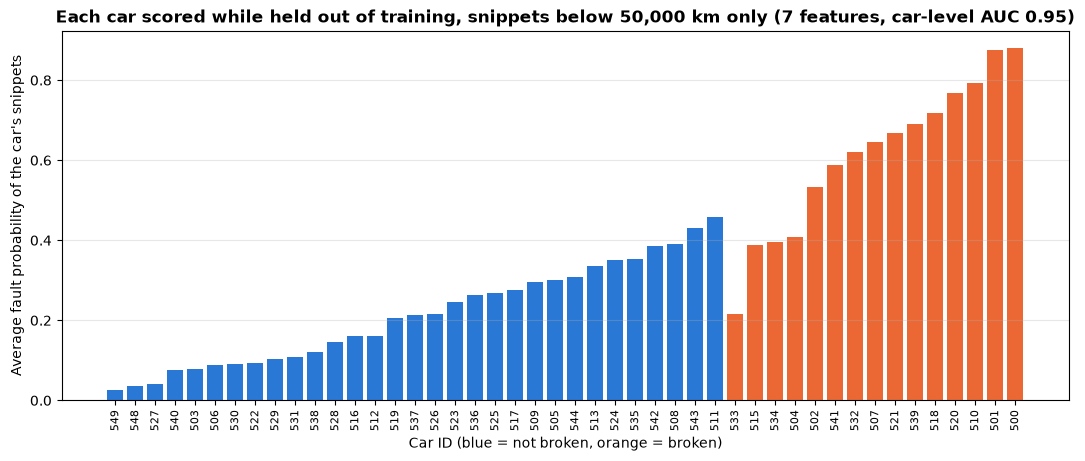

Car cutoffs chosen on the training cars of the 7 folds: [0.33, 0.36, 0.38, 0.39, 0.42, 0.43]
Broken cars caught: 12 of 15 | not-broken cars flagged: 4 of 31


,car,label,rows,mean_p,share_flagged,car_cutoff,flagged
0,500,1,4096,0.879,0.963,0.38,1
1,501,1,3795,0.875,0.965,0.38,1
2,510,1,4917,0.792,0.917,0.36,1
3,520,1,1215,0.769,0.961,0.33,1
4,518,1,1393,0.719,0.844,0.39,1
5,539,1,965,0.691,0.840,0.42,1
6,521,1,6085,0.668,0.818,0.33,1
7,507,1,792,0.645,0.782,0.38,1
8,532,1,1648,0.620,0.802,0.43,1
9,541,1,3079,0.589,0.725,0.36,1


In [8]:
one = car_results[(car_results["config"] == "7 features") & (car_results["rep"] == 0)].sort_values(["label", "mean_p"]).reset_index(drop=True)
one["flagged"] = (one["mean_p"] >= one["car_cutoff"]).astype(int)
auc_one = roc_auc_score(one["label"], one["mean_p"])

plt.figure(figsize=(13, 4.8))
plt.bar(range(len(one)), one["mean_p"], color=np.where(one["label"] == 1, ORANGE, BLUE))
plt.xticks(range(len(one)), one["car"].astype(int), rotation=90, fontsize=8)
plt.ylabel("Average fault probability of the car's snippets"); plt.xlabel("Car ID (blue = not broken, orange = broken)")
plt.title(f"Each car scored while held out of training, snippets below {MILEAGE_CAP:,} km only (7 features, car-level AUC {auc_one:.2f})", fontweight="bold")
plt.grid(axis="y", alpha=0.3); plt.show()

print("Car cutoffs chosen on the training cars of the 7 folds:", sorted(set(one["car_cutoff"].round(2).tolist())))
print("Broken cars caught: %d of %d | not-broken cars flagged: %d of %d" % (
    one.loc[one["label"] == 1, "flagged"].sum(), (one["label"] == 1).sum(), one.loc[one["label"] == 0, "flagged"].sum(), (one["label"] == 0).sum()))
one[["car", "label", "rows", "mean_p", "share_flagged", "car_cutoff", "flagged"]].sort_values("mean_p", ascending=False).round(3).reset_index(drop=True)

In [ ]:
# ---------------- 6. Does the cap matter? ----------------
#
# The same run for the 7-feature model at a 30,000 km cap, the 50,000 km cap, an 80,000 km cap, and with no cap at all (all 49 cars, the work4 setting, re-run here so that the comparison is same code, same machine). Each is one repeat (REPEATS = 1), so the 50,000 km row is the first repeat of section 4 again. The cars change with the cap: 46 cars below 30,000 and 50,000 km, 47 below 80,000 km (car 514 comes back in), 49 with no cap. The higher the cap, the more of the broken cars' high-mileage life the model gets to see.

In [9]:
CAPS = [30_000, 50_000, 80_000, None]
sweep_rows = []
for cap in CAPS:
    name = "all mileage" if cap is None else f"below {cap:,} km"
    f, c, p = run_cv(cut_at(fe, cap), {"7 features": CONFIGS["7 features"]}, repeats=1, tag=f"{name}, ")
    sweep_rows.append(summarise(f, c, p).iloc[0].rename(name))
sweep = pd.DataFrame(sweep_rows)
sweep[["cars", "broken cars", "snippets", "snippet AUC (pooled)", "fold AUC range", "car AUC", "recall %", "false alarms %", "broken caught", "not broken flagged"]].round(ROUND)

below 30,000 km, repeat 1 of 1 done


below 50,000 km, repeat 1 of 1 done


below 80,000 km, repeat 1 of 1 done


all mileage, repeat 1 of 1 done


,cars,broken cars,snippets,snippet AUC (pooled),fold AUC range,car AUC,recall %,false alarms %,broken caught,not broken flagged
"below 30,000 km",46,15,62202,0.874,0.83 to 0.98,0.957,84.1,26.3,13.0 of 15,5.0 of 31
"below 50,000 km",46,15,89577,0.876,0.72 to 0.97,0.953,80.6,23.2,12.0 of 15,4.0 of 31
"below 80,000 km",47,16,126223,0.870,0.54 to 0.94,0.929,76.8,23.0,12.0 of 16,5.0 of 31
all mileage,49,16,176327,0.851,0.72 to 0.89,0.936,86.3,39.3,14.0 of 16,10.0 of 33


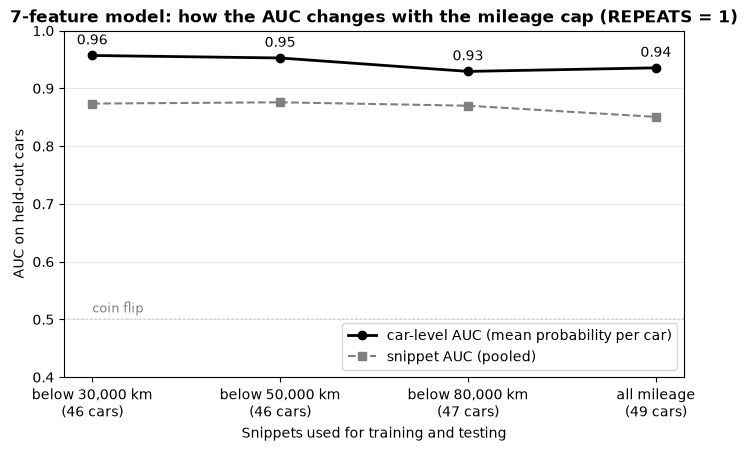

In [10]:
x = np.arange(len(sweep))
plt.figure(figsize=(8, 4.5))
plt.plot(x, sweep["car AUC"].astype(float), color="black", marker="o", linewidth=2, label="car-level AUC (mean probability per car)")
plt.plot(x, sweep["snippet AUC (pooled)"].astype(float), color="gray", marker="s", linewidth=1.5, linestyle="--", label="snippet AUC (pooled)")
for i, v in enumerate(sweep["car AUC"].astype(float)):
    plt.annotate(f"{v:.2f}", (i, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=10)
plt.axhline(0.5, color="lightgray", linestyle=":", linewidth=1.2)
plt.text(0, 0.512, "coin flip", color="gray", fontsize=9, ha="left")
plt.xticks(x, [f"{i}\n({int(n)} cars)" for i, n in zip(sweep.index, sweep["cars"])])
plt.ylim(0.4, 1.0); plt.ylabel("AUC on held-out cars"); plt.xlabel("Snippets used for training and testing")
plt.title("7-feature model: how the AUC changes with the mileage cap (REPEATS = 1)", fontweight="bold")
plt.legend(loc="lower right"); plt.grid(axis="y", alpha=0.3); plt.show()

In [ ]:
# ---------------- 7. Sanity check: shuffled car labels ----------------
#
# One way the numbers above could be wrong is a leak in the code, something that lets the model recognise the test cars. The check is to hand the 46 cars random labels (15 "broken" and 31 "not broken", drawn three times with different seeds) and run the 7-feature model once on each. With random labels there is nothing to learn, so a clean pipeline should land near a car-level AUC of 0.5. This only tests the code: it cannot tell battery health apart from any other car-level difference, which is the point taken up in the conclusion.

In [11]:
true_labels = low.groupby("car")["label"].first()
shuffle_rows = []
for seed in (0, 1, 2):
    fake = pd.Series(np.random.RandomState(seed).permutation(true_labels.values), index=true_labels.index)
    shuffled = low.assign(label=low["car"].map(fake).values)
    f, c, p = run_cv(shuffled, {"7 features": CONFIGS["7 features"]}, repeats=1, tag=f"shuffled labels, seed {seed}, ")
    shuffle_rows.append(summarise(f, c, p).iloc[0].rename(f"shuffled labels, seed {seed}"))
pd.DataFrame(shuffle_rows)[["snippet AUC (pooled)", "fold AUC range", "car AUC", "recall %", "false alarms %", "broken caught", "not broken flagged"]].round(ROUND)

shuffled labels, seed 0, repeat 1 of 1 done


shuffled labels, seed 1, repeat 1 of 1 done


shuffled labels, seed 2, repeat 1 of 1 done


,snippet AUC (pooled),fold AUC range,car AUC,recall %,false alarms %,broken caught,not broken flagged
"shuffled labels, seed 0",0.388,0.17 to 0.63,0.374,55.2,76.6,4.0 of 15,13.0 of 31
"shuffled labels, seed 1",0.313,0.22 to 0.47,0.385,69.5,86.3,7.0 of 15,17.0 of 31
"shuffled labels, seed 2",0.570,0.35 to 0.82,0.512,97.8,96.5,5.0 of 15,16.0 of 31


In [ ]:
# ---------------- 8. Conclusion ----------------
#
# The model still tells broken cars from not-broken ones when mileage is held fixed. On snippets below 50,000 km, where every car is seen at the same age, the 7-feature model reaches a car-level AUC of 0.95 (0.92 to 0.96 over the five repeats) and a pooled snippet AUC of 0.87, against 0.94 and 0.86 in work4 with all mileage. The 12-feature model does the same (0.96 and 0.88). At the car cutoff chosen on training cars, 12.8 of the 15 broken cars are caught and 3.6 of the 31 not-broken cars are flagged, about the hit rate of work4 (12.6 of 16) with fewer false alarms (6.0 of 33). At the snippet level the validation-chosen cutoff lands on a different trade-off, recall 80 % with 25 % false alarms against 88 % and 38 % in work4, so the AUC, which does not depend on a cutoff, is the fairer comparison. Fold-level AUC still swings from fold to fold (0.71 to 0.98), as it did in work4, and with 15 broken cars none of these numbers is precise, but the picture is the same in every repeat.
#
# Three details back this up:
#
# - The cap does not matter. The car-level AUC is 0.96 below 30,000 km, 0.95 below 50,000 km, 0.93 below 80,000 km and 0.94 with no cap (section 6). If the model depended on seeing the broken cars' high-mileage life, the low caps would have pulled it down. They did not.
# - Mileage stops helping once the mileage ranges overlap. Adding it to the 7 features lowers the snippet AUC from 0.87 to 0.84 and raises false alarms from 25 % to 29 %. Within 0 to 50,000 km it is noise, so the 0.86 it bought in work4 came from the high-mileage end that this cut removes.
# - With shuffled labels the same pipeline drops to a car-level AUC of 0.37 to 0.51 (section 7), so the result is not a leak in the code.
#
# The four broken cars whose whole recorded life is below the cap (533, 534, 539, 541) are the cleanest test, because nothing about them can come from high mileage: in the first repeat three are caught (534 only just) and 533 is missed, with 504 and 515 the other two misses.
#
# What this means for the proposal's worry. The worry was that the model scores well because it learnt that high mileage and heavy recording go with the broken label in this fleet. The numbers do not support that: the separation is as strong at equal mileage as with all mileage, and adding mileage inside the window makes things worse. The signal is in the charging telemetry itself, in combinations the model reads snippet by snippet, even though no single signal's typical level separates the groups (work5: car-level AUC 0.35 to 0.54 per signal). What this notebook cannot rule out is a different kind of fleet effect: a car-level difference that is not mileage, such as vehicle type, charger or usage pattern, would survive this cut just as well. Testing that needs either a second fleet or features that describe how a car is charged (share of fast-charging snippets, time spent at 100 %), as suggested at the end of work5.

In [ ]:
# INTERESTING THINGS I FOUND THIS WEEK
# 1. The model still tells broken cars from not broken ones when every car is seen at the same age (under 50,000 km): car level AUC 0.95 against 0.94 with all mileage.
#    So the week 4 worry ("it only learned high mileage = broken") is not what the numbers say. The signal is in the charging telemetry itself.
# 2. The cap does not matter: car AUC 0.96 under 30,000 km, 0.95 under 50,000 km, 0.93 under 80,000 km, 0.94 with no cap.
# 3. Mileage stops helping inside the window: adding it drops the snippet AUC from 0.87 to 0.84 and raises false alarms from 25% to 29%.
# 4. With shuffled car labels the same code drops to a car AUC of 0.37 to 0.51, so the result is not a leak in the code.
# 5. The 4 broken cars that never left the window (533, 534, 539, 541) are the cleanest test: 3 are caught (534 only just) and 533 is missed.
# 6. What this cannot rule out: a car level difference that is not mileage (vehicle type, charger, usage pattern) would survive this cut just as well.
#    work5 found exactly such a usage pattern in the 4 low mileage broken cars (kept at low charge level, charged gently).
#
# WHAT I WILL RESEARCH NEXT
# - Test on cars from another fleet: the same figshare release has 2 more fleets in the same file format (217 cars / 31 broken and 198 cars / 1 broken).
#   Train on our 49 cars, score the other fleets held out completely, and use the 198 car fleet as a false alarm test.
# - Add usage features (share of time under 20% charge, share of fast charging) and the raw cell imbalance and temperature columns, and see which the model prefers.
# - Align the served API with a validated cutoff (it still uses 0.15 from work3) before anything else is built on it.